# Construction Project Analytics & Predictive Modelling — Version 2

## Phase 1: Dataset Engineering, Data Semantics & Quality Assurance

**Portfolio objective:** Build a reproducible construction project-controls dataset that can support defensible machine-learning experiments for next-month delay risk, monthly cost forecasting and physical-progress forecasting.

> **Version-control rule:** Version 1 is archived unchanged in `archive_v1/`. This notebook is a separate Version 2 workstream.

### What changes in Version 2?

| Dimension | Version 1 | Version 2 |
|---|---:|---:|
| Projects | 5 | 30 |
| Work categories | 10 | 10 |
| Reporting periods | 12 months | 24 months |
| Observations | 600 | 7,200 |
| Cost semantics | Cost field behaved like cumulative-to-date cost | Monthly expenditure and cumulative expenditure are separate |
| Progress semantics | Cumulative progress | Monthly progress increment and cumulative progress are separate |
| Operational drivers | Limited | Labour, procurement, design changes, material prices and rainfall |
| Temporal risk behaviour | Mostly independent monthly delay noise | Persistent project-level conditions create temporal signal |

**Important:** The Version 2 dataset is still synthetic. More rows and more realistic simulation logic improve the quality of the exercise, but they do not make the data real or establish production performance.

## 1. Business problems and prediction grain

The analytical unit is one **project × work category × reporting month** record.

We will build three distinct prediction tasks in later phases:

1. **Next-month delay risk (classification):** predict whether the next month's recorded delay will be at least 12 days.
2. **Next-month expenditure (regression):** predict next month's actual monthly expenditure in ₹ crore.
3. **Next-month physical progress (regression):** predict the next month's actual progress increment in percentage points.

### Forecast origin

Each prediction is made at the end of month *t*, using information available at that point. The target is the outcome in month *t + 1*.

The approved baseline schedule and budget are assumed to be available in advance. Therefore, the next month's **planned** progress and cost may be used as known-future inputs. Next month's **actual** delay, expenditure and progress are targets only and must never enter the feature matrix.

### Two simulator-only columns

- `risk_state_simulated`
- `productivity_factor_simulated`

These are hidden simulator diagnostics. They help us understand how the synthetic data was generated, but they would not be directly observable in a real project. They must be excluded from all model features.

## 2. Set up the environment

The notebook supports execution from either the repository root or the `notebooks/` directory. The generator is maintained as a reusable Python module under `src/` rather than duplicated inside the notebook.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data_v2"
OUTPUT_DIR = PROJECT_ROOT / "outputs_v2"
VISUALIZATION_DIR = OUTPUT_DIR / "visualizations"

for folder in [DATA_DIR, OUTPUT_DIR, VISUALIZATION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from synthetic_data import generate_construction_dataset, validate_construction_dataset

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: /mnt/data/Construction_Project_Analytics_V2
Data directory: /mnt/data/Construction_Project_Analytics_V2/data_v2
Output directory: /mnt/data/Construction_Project_Analytics_V2/outputs_v2


## 3. Generate the Version 2 dataset

The generator is deterministic for a fixed random seed. Re-running the cell with `RANDOM_STATE = 42` recreates the same records.

### Dataset design

- 30 projects, assigned across six synthetic contractors.
- 10 work categories per project.
- 24 monthly periods from January 2025 through December 2026.
- 30 × 10 × 24 = **7,200 observations**.
- Project and work-package budgets reconcile to the project contract value.
- Actual progress is cumulative and non-decreasing.
- Actual monthly expenditure is distinct from cumulative expenditure.
- Project-level operating conditions evolve over time, creating temporal dependence.

In [2]:
data = generate_construction_dataset(
    seed=RANDOM_STATE,
    n_projects=30,
    n_months=24,
)

print("Dataset generated successfully.")
print("Shape:", data.shape)
print("Projects:", data["project_id"].nunique())
print("Work categories:", data["work_category"].nunique())
print("Contractors:", data["contractor"].nunique())
print("Reporting months:", data["month"].nunique())
print("Date range:", data["month"].min().date(), "to", data["month"].max().date())

display(data.head(10))

Dataset generated successfully.
Shape: (7200, 32)
Projects: 30
Work categories: 10
Contractors: 6
Reporting months: 24
Date range: 2025-01-01 to 2026-12-01


,project_id,project_name,contractor,work_category,month,month_index,contract_value_cr,package_budget_cr,baseline_start_month,baseline_duration_months,planned_progress_increment_pct,planned_progress_pct,actual_progress_increment_pct,actual_progress_pct,planned_cost_month_cr,actual_cost_month_cr,cumulative_actual_cost_cr,delay_days,labour_shortage_pct,procurement_delay_days,design_change_count,material_price_index,rainfall_mm,risk_state_simulated,productivity_factor_simulated,PV_cr,EV_cr,AC_cr,SV_cr,CV_cr,SPI,CPI
0,PRJ-001,Project 01,Contractor A,Earthwork,2025-01-01,1,53.020,2.658,2,19,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4,4.956,2,0,1.008,13.415,0.088,0.751,0.000,0.000,0.000,0.000,0.000,NaN,NaN
1,PRJ-001,Project 01,Contractor A,Earthwork,2025-02-01,2,53.020,2.658,2,19,1.698,1.698,1.404,1.404,0.045,0.047,0.047,5,1.726,2,0,1.022,27.006,0.000,0.827,0.045,0.037,0.047,-0.008,-0.010,0.827,0.786
2,PRJ-001,Project 01,Contractor A,Earthwork,2025-03-01,3,53.020,2.658,2,19,2.887,4.585,2.668,4.072,0.077,0.081,0.129,5,5.567,1,0,1.023,17.755,0.017,0.924,0.122,0.108,0.129,-0.014,-0.020,0.888,0.842
3,PRJ-001,Project 01,Contractor A,Earthwork,2025-04-01,4,53.020,2.658,2,19,3.935,8.520,2.521,6.593,0.105,0.114,0.242,4,13.315,2,0,1.023,9.877,0.304,0.641,0.226,0.175,0.242,-0.051,-0.067,0.774,0.723
4,PRJ-001,Project 01,Contractor A,Earthwork,2025-05-01,5,53.020,2.658,2,19,4.844,13.364,3.196,9.788,0.129,0.144,0.387,7,15.755,2,1,1.043,82.100,0.156,0.660,0.355,0.260,0.387,-0.095,-0.126,0.732,0.673
5,PRJ-001,Project 01,Contractor A,Earthwork,2025-06-01,6,53.020,2.658,2,19,5.613,18.977,4.677,14.465,0.149,0.154,0.541,5,13.438,1,0,1.067,191.363,0.174,0.833,0.504,0.384,0.541,-0.120,-0.156,0.762,0.711
6,PRJ-001,Project 01,Contractor A,Earthwork,2025-07-01,7,53.020,2.658,2,19,6.242,25.218,4.785,19.250,0.166,0.173,0.714,6,4.413,1,0,1.069,204.415,0.000,0.767,0.670,0.512,0.714,-0.159,-0.202,0.763,0.717
7,PRJ-001,Project 01,Contractor A,Earthwork,2025-08-01,8,53.020,2.658,2,19,6.731,31.949,5.483,24.734,0.179,0.202,0.916,5,9.704,2,0,1.047,193.723,0.152,0.815,0.849,0.657,0.916,-0.192,-0.258,0.774,0.718
8,PRJ-001,Project 01,Contractor A,Earthwork,2025-09-01,9,53.020,2.658,2,19,7.080,39.030,5.270,30.004,0.188,0.199,1.115,5,8.617,1,0,1.070,138.949,0.089,0.744,1.037,0.797,1.115,-0.240,-0.318,0.769,0.715
9,PRJ-001,Project 01,Contractor A,Earthwork,2025-10-01,10,53.020,2.658,2,19,7.290,46.320,5.927,35.931,0.194,0.202,1.317,5,8.144,2,0,1.091,48.085,0.116,0.813,1.231,0.955,1.317,-0.276,-0.362,0.776,0.725


## 4. Understand the revised data semantics

This is the most important design correction in Version 2. Similar-looking columns represent different business concepts and must not be mixed.

| Variable | Meaning | Type |
|---|---|---|
| `planned_progress_increment_pct` | Baseline progress planned during this month | Monthly increment |
| `actual_progress_increment_pct` | Physical progress achieved during this month | Monthly increment |
| `planned_progress_pct` | Baseline cumulative physical progress to date | Cumulative |
| `actual_progress_pct` | Actual cumulative physical progress to date | Cumulative |
| `planned_cost_month_cr` | Planned expenditure during this month | Monthly flow |
| `actual_cost_month_cr` | Actual expenditure during this month | Monthly flow |
| `cumulative_actual_cost_cr` | Actual expenditure accumulated to date | Cumulative |
| `PV_cr` | Cumulative planned value | EVM cumulative measure |
| `EV_cr` | Cumulative earned value | EVM cumulative measure |
| `AC_cr` | Cumulative actual cost | EVM cumulative measure |

**Why this matters:** A forecast of next-month expenditure must target `actual_cost_month_cr` shifted forward by one month. It should not accidentally target a cumulative-to-date amount and describe it as monthly expenditure.

In [3]:
semantic_columns = [
    "project_id", "project_name", "contractor", "work_category", "month",
    "planned_progress_increment_pct", "actual_progress_increment_pct",
    "planned_progress_pct", "actual_progress_pct",
    "planned_cost_month_cr", "actual_cost_month_cr", "cumulative_actual_cost_cr",
    "delay_days", "labour_shortage_pct", "procurement_delay_days",
    "design_change_count", "material_price_index", "rainfall_mm",
    "PV_cr", "EV_cr", "AC_cr", "SV_cr", "CV_cr", "SPI", "CPI",
]
display(data[semantic_columns].head(12))

,project_id,project_name,contractor,work_category,month,planned_progress_increment_pct,actual_progress_increment_pct,planned_progress_pct,actual_progress_pct,planned_cost_month_cr,actual_cost_month_cr,cumulative_actual_cost_cr,delay_days,labour_shortage_pct,procurement_delay_days,design_change_count,material_price_index,rainfall_mm,PV_cr,EV_cr,AC_cr,SV_cr,CV_cr,SPI,CPI
0,PRJ-001,Project 01,Contractor A,Earthwork,2025-01-01,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4,4.956,2,0,1.008,13.415,0.000,0.000,0.000,0.000,0.000,NaN,NaN
1,PRJ-001,Project 01,Contractor A,Earthwork,2025-02-01,1.698,1.404,1.698,1.404,0.045,0.047,0.047,5,1.726,2,0,1.022,27.006,0.045,0.037,0.047,-0.008,-0.010,0.827,0.786
2,PRJ-001,Project 01,Contractor A,Earthwork,2025-03-01,2.887,2.668,4.585,4.072,0.077,0.081,0.129,5,5.567,1,0,1.023,17.755,0.122,0.108,0.129,-0.014,-0.020,0.888,0.842
3,PRJ-001,Project 01,Contractor A,Earthwork,2025-04-01,3.935,2.521,8.520,6.593,0.105,0.114,0.242,4,13.315,2,0,1.023,9.877,0.226,0.175,0.242,-0.051,-0.067,0.774,0.723
4,PRJ-001,Project 01,Contractor A,Earthwork,2025-05-01,4.844,3.196,13.364,9.788,0.129,0.144,0.387,7,15.755,2,1,1.043,82.100,0.355,0.260,0.387,-0.095,-0.126,0.732,0.673
5,PRJ-001,Project 01,Contractor A,Earthwork,2025-06-01,5.613,4.677,18.977,14.465,0.149,0.154,0.541,5,13.438,1,0,1.067,191.363,0.504,0.384,0.541,-0.120,-0.156,0.762,0.711
6,PRJ-001,Project 01,Contractor A,Earthwork,2025-07-01,6.242,4.785,25.218,19.250,0.166,0.173,0.714,6,4.413,1,0,1.069,204.415,0.670,0.512,0.714,-0.159,-0.202,0.763,0.717
7,PRJ-001,Project 01,Contractor A,Earthwork,2025-08-01,6.731,5.483,31.949,24.734,0.179,0.202,0.916,5,9.704,2,0,1.047,193.723,0.849,0.657,0.916,-0.192,-0.258,0.774,0.718
8,PRJ-001,Project 01,Contractor A,Earthwork,2025-09-01,7.080,5.270,39.030,30.004,0.188,0.199,1.115,5,8.617,1,0,1.070,138.949,1.037,0.797,1.115,-0.240,-0.318,0.769,0.715
9,PRJ-001,Project 01,Contractor A,Earthwork,2025-10-01,7.290,5.927,46.320,35.931,0.194,0.202,1.317,5,8.144,2,0,1.091,48.085,1.231,0.955,1.317,-0.276,-0.362,0.776,0.725


## 5. Data-quality and domain validation

We validate more than null counts. The checks cover the reporting grain, physical-progress bounds, monotonic cumulative values and financial reconciliation.

### Expected missing values

`SPI` may be undefined before planned value exists. `CPI` may be undefined before actual cost exists. These are legitimate undefined ratios, not arbitrary missing source records. All other columns should be populated.

In [4]:
quality_report = validate_construction_dataset(data)
quality_df = pd.DataFrame(
    [{"check": key, "result": value} for key, value in quality_report.items()]
)
display(quality_df)

assert quality_report["passed"], "One or more dataset-quality checks failed."
assert set(data.columns[data.isna().any()]) <= {"SPI", "CPI"}

print("All required data-quality checks passed.")

,check,result
0,rows,7200
1,columns,32
2,projects,30
3,work_categories,10
4,reporting_months,24
5,duplicate_grain_rows,0
6,missing_cells,896
7,columns_with_expected_missing_values,"CPI, SPI"
8,unexpected_missing_columns,
9,negative_monthly_cost_rows,0


All required data-quality checks passed.


### 5.1 Check reporting grain and time coverage

The composite key must be unique: one row per project, work category and month.

In [5]:
grain_check = (
    data.groupby(["project_id", "work_category"], as_index=False)
        .agg(row_count=("month", "size"), unique_months=("month", "nunique"))
)

display(grain_check.head())
print("Minimum rows per project-work-category:", grain_check["row_count"].min())
print("Maximum rows per project-work-category:", grain_check["row_count"].max())
print("All groups have 24 months:", bool((grain_check["row_count"] == 24).all()))
print("Unique composite keys:", not data.duplicated(["project_id", "work_category", "month"]).any())

,project_id,work_category,row_count,unique_months
0,PRJ-001,Earthwork,24,24
1,PRJ-001,Electrical,24,24
2,PRJ-001,External Works,24,24
3,PRJ-001,Fire Fighting,24,24
4,PRJ-001,Flooring,24,24


Minimum rows per project-work-category: 24
Maximum rows per project-work-category: 24
All groups have 24 months: True
Unique composite keys: True


### 5.2 Reconcile monthly and cumulative cost

For each project-work-category series:

\[
\text{Cumulative Actual Cost}_t = \sum_{i=1}^{t}\text{Actual Monthly Cost}_i
\]

This check protects the expenditure target from a common semantic error.

In [6]:
cost_reconciliation = data.copy()
cost_reconciliation["recomputed_cumulative_cost_cr"] = (
    cost_reconciliation.groupby(["project_id", "work_category"])["actual_cost_month_cr"].cumsum()
)
cost_reconciliation["cost_reconciliation_error_cr"] = (
    cost_reconciliation["cumulative_actual_cost_cr"]
    - cost_reconciliation["recomputed_cumulative_cost_cr"]
)

print(
    "Maximum absolute cumulative-cost reconciliation error (₹ Cr):",
    cost_reconciliation["cost_reconciliation_error_cr"].abs().max(),
)

Maximum absolute cumulative-cost reconciliation error (₹ Cr): 3.552713678800501e-15


### 5.3 Reconcile planned package budgets to contract value

The sum of all work-package budgets for a project must equal its contract value (the synthetic equivalent of the budget at completion for this exercise).

In [7]:
project_budget_check = (
    data.drop_duplicates(["project_id", "work_category"])
        .groupby("project_id", as_index=False)
        .agg(
            contract_value_cr=("contract_value_cr", "first"),
            total_package_budget_cr=("package_budget_cr", "sum"),
        )
)
project_budget_check["reconciliation_error_cr"] = (
    project_budget_check["total_package_budget_cr"]
    - project_budget_check["contract_value_cr"]
)
display(project_budget_check.head(10))
print("Maximum absolute budget reconciliation error:", project_budget_check["reconciliation_error_cr"].abs().max())

,project_id,contract_value_cr,total_package_budget_cr,reconciliation_error_cr
0,PRJ-001,53.020,53.020,0.000
1,PRJ-002,62.469,62.469,0.000
2,PRJ-003,57.557,57.557,0.000
3,PRJ-004,23.135,23.135,0.000
4,PRJ-005,15.807,15.807,0.000
5,PRJ-006,45.655,45.655,0.000
6,PRJ-007,62.285,62.285,0.000
7,PRJ-008,23.126,23.126,-0.000
8,PRJ-009,61.786,61.786,0.000
9,PRJ-010,60.741,60.741,0.000


Maximum absolute budget reconciliation error: 7.105427357601002e-15


## 6. Exploratory checks on the new synthetic data

These charts are sanity checks on the simulation. They are not findings about real construction projects.

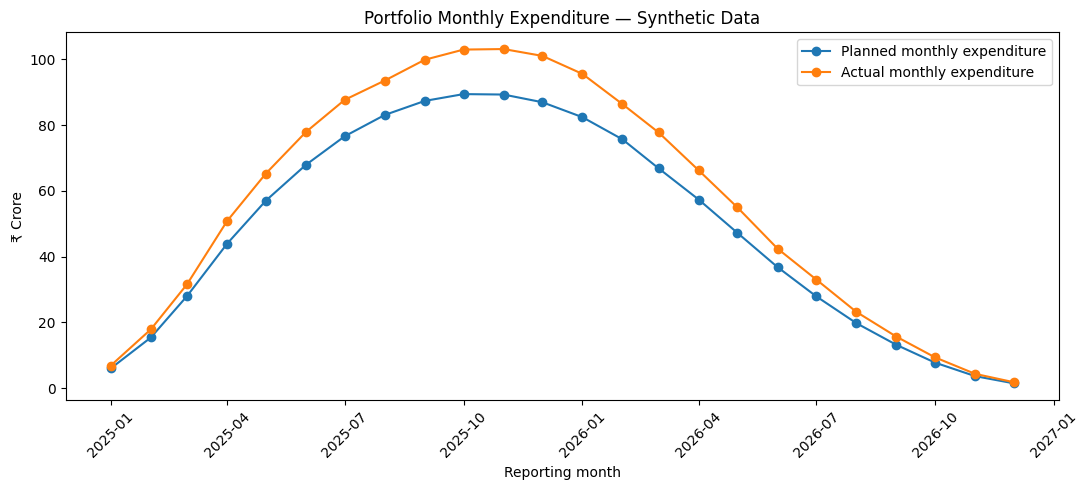

In [8]:
monthly_portfolio = (
    data.groupby("month", as_index=False)
        .agg(
            planned_expenditure_cr=("planned_cost_month_cr", "sum"),
            actual_expenditure_cr=("actual_cost_month_cr", "sum"),
            planned_progress_increment_pct=("planned_progress_increment_pct", "mean"),
            actual_progress_increment_pct=("actual_progress_increment_pct", "mean"),
            average_delay_days=("delay_days", "mean"),
        )
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_portfolio["month"], monthly_portfolio["planned_expenditure_cr"], marker="o", label="Planned monthly expenditure")
plt.plot(monthly_portfolio["month"], monthly_portfolio["actual_expenditure_cr"], marker="o", label="Actual monthly expenditure")
plt.title("Portfolio Monthly Expenditure — Synthetic Data")
plt.ylabel("₹ Crore")
plt.xlabel("Reporting month")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_01_monthly_expenditure.png", dpi=160, bbox_inches="tight")
plt.show()

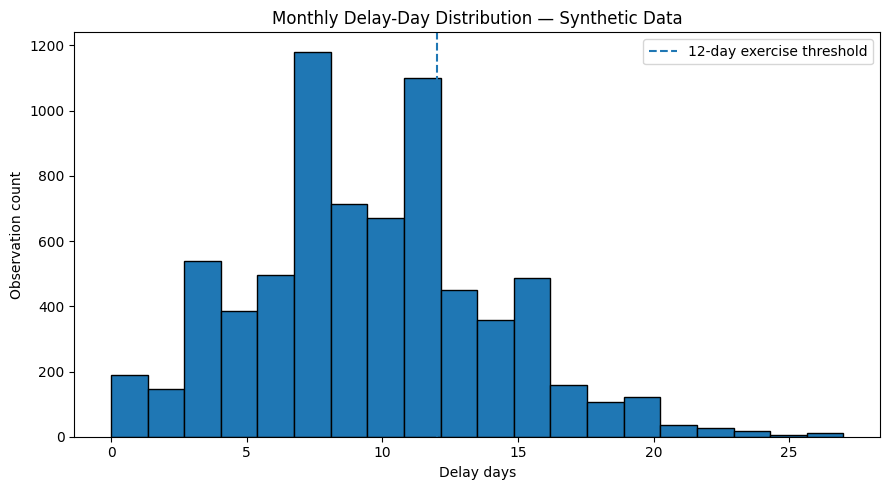

Share of records with delay >= 12 days: 0.319


In [9]:
plt.figure(figsize=(9, 5))
plt.hist(data["delay_days"], bins=20, edgecolor="black")
plt.axvline(12, linestyle="--", label="12-day exercise threshold")
plt.title("Monthly Delay-Day Distribution — Synthetic Data")
plt.xlabel("Delay days")
plt.ylabel("Observation count")
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_02_delay_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("Share of records with delay >= 12 days:", round((data["delay_days"] >= 12).mean(), 3))

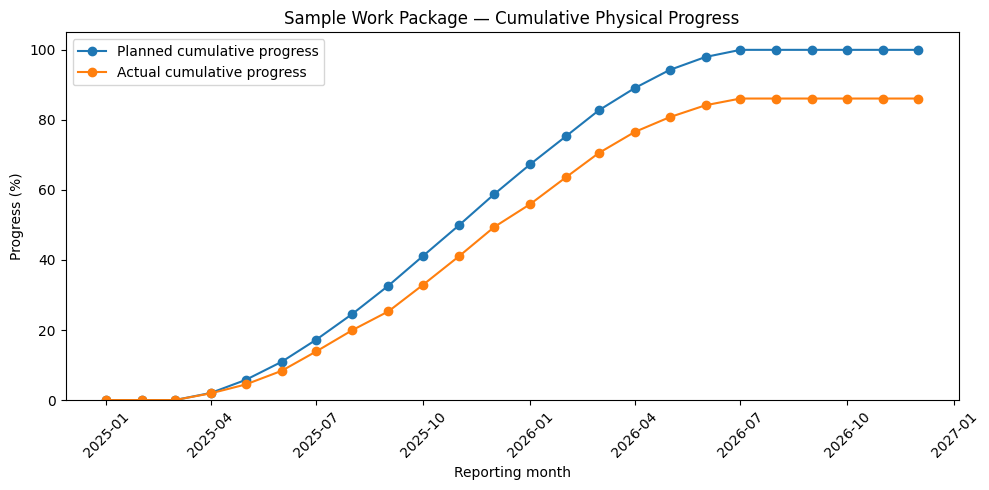

In [10]:
sample_series = data[
    (data["project_id"] == "PRJ-001")
    & (data["work_category"] == "RCC")
].sort_values("month")

plt.figure(figsize=(10, 5))
plt.plot(sample_series["month"], sample_series["planned_progress_pct"], marker="o", label="Planned cumulative progress")
plt.plot(sample_series["month"], sample_series["actual_progress_pct"], marker="o", label="Actual cumulative progress")
plt.title("Sample Work Package — Cumulative Physical Progress")
plt.ylabel("Progress (%)")
plt.xlabel("Reporting month")
plt.ylim(0, 105)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_03_sample_progress_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Data dictionary

The dictionary distinguishes observable project-control inputs from simulator-only diagnostics. The latter are excluded from modelling.

In [11]:
data_dictionary = pd.DataFrame([
    ("project_id", "Project identifier", "Categorical", "Observable"),
    ("project_name", "Project display name", "Categorical", "Observable"),
    ("contractor", "Assigned synthetic contractor", "Categorical", "Observable"),
    ("work_category", "Work package / discipline", "Categorical", "Observable"),
    ("month", "Monthly reporting period", "Date", "Observable"),
    ("month_index", "Sequential month number", "Numeric", "Observable"),
    ("contract_value_cr", "Project contract value, ₹ crore", "Numeric", "Observable"),
    ("package_budget_cr", "Work-package budget, ₹ crore", "Numeric", "Observable"),
    ("baseline_start_month", "Approved baseline start month index", "Numeric", "Known baseline"),
    ("baseline_duration_months", "Approved baseline duration", "Numeric", "Known baseline"),
    ("planned_progress_increment_pct", "Planned progress in the current month", "Numeric", "Known baseline"),
    ("planned_progress_pct", "Cumulative planned progress", "Numeric", "Known baseline"),
    ("actual_progress_increment_pct", "Actual progress achieved in current month", "Numeric", "Observed outcome"),
    ("actual_progress_pct", "Cumulative actual physical progress", "Numeric", "Observed outcome"),
    ("planned_cost_month_cr", "Planned current-month expenditure, ₹ crore", "Numeric", "Known baseline"),
    ("actual_cost_month_cr", "Actual current-month expenditure, ₹ crore", "Numeric", "Observed outcome"),
    ("cumulative_actual_cost_cr", "Cumulative actual expenditure, ₹ crore", "Numeric", "Observed outcome"),
    ("delay_days", "Recorded delay days in current reporting month", "Numeric", "Observed outcome"),
    ("labour_shortage_pct", "Estimated labour shortage percentage", "Numeric", "Observed driver"),
    ("procurement_delay_days", "Procurement-related delay days", "Numeric", "Observed driver"),
    ("design_change_count", "Count of design changes recorded in month", "Numeric", "Observed driver"),
    ("material_price_index", "Synthetic material-price index", "Numeric", "Observed driver"),
    ("rainfall_mm", "Synthetic monthly rainfall, millimetres", "Numeric", "Observed driver"),
    ("risk_state_simulated", "Latent project risk state used by simulator", "Numeric", "SIMULATOR ONLY — EXCLUDE"),
    ("productivity_factor_simulated", "Latent productivity multiplier used by simulator", "Numeric", "SIMULATOR ONLY — EXCLUDE"),
    ("PV_cr", "Cumulative planned value, ₹ crore", "Numeric", "Derived EVM"),
    ("EV_cr", "Cumulative earned value, ₹ crore", "Numeric", "Derived EVM"),
    ("AC_cr", "Cumulative actual cost, ₹ crore", "Numeric", "Derived EVM"),
    ("SV_cr", "Schedule variance = EV − PV, ₹ crore", "Numeric", "Derived EVM"),
    ("CV_cr", "Cost variance = EV − AC, ₹ crore", "Numeric", "Derived EVM"),
    ("SPI", "Schedule performance index = EV / PV", "Numeric", "Derived EVM"),
    ("CPI", "Cost performance index = EV / AC", "Numeric", "Derived EVM"),
], columns=["column", "definition", "data_type", "availability"])

display(data_dictionary)


,column,definition,data_type,availability
0,project_id,Project identifier,Categorical,Observable
1,project_name,Project display name,Categorical,Observable
2,contractor,Assigned synthetic contractor,Categorical,Observable
3,work_category,Work package / discipline,Categorical,Observable
4,month,Monthly reporting period,Date,Observable
5,month_index,Sequential month number,Numeric,Observable
6,contract_value_cr,"Project contract value, ₹ crore",Numeric,Observable
7,package_budget_cr,"Work-package budget, ₹ crore",Numeric,Observable
8,baseline_start_month,Approved baseline start month index,Numeric,Known baseline
9,baseline_duration_months,Approved baseline duration,Numeric,Known baseline


## 8. Export Version 2 data and quality artifacts

All Version 2 outputs use separate directories. Existing Version 1 outputs are not overwritten.

In [12]:
dataset_path = DATA_DIR / "construction_project_monthly_v2.csv"
quality_path = OUTPUT_DIR / "data_quality_report_v2.csv"
dictionary_path = OUTPUT_DIR / "data_dictionary_v2.csv"
summary_path = OUTPUT_DIR / "project_month_summary_v2.csv"

data.to_csv(dataset_path, index=False)
pd.DataFrame([quality_report]).to_csv(quality_path, index=False)
data_dictionary.to_csv(dictionary_path, index=False)
monthly_portfolio.to_csv(summary_path, index=False)

print("Saved:")
for path in [dataset_path, quality_path, dictionary_path, summary_path]:
    print("-", path.relative_to(PROJECT_ROOT), f"({path.stat().st_size:,} bytes)")

Saved:
- data_v2/construction_project_monthly_v2.csv (3,116,860 bytes)
- outputs_v2/data_quality_report_v2.csv (543 bytes)
- outputs_v2/data_dictionary_v2.csv (2,435 bytes)
- outputs_v2/project_month_summary_v2.csv (2,468 bytes)


## 9. Phase 1 completion checklist

- [x] Version 1 archived without modification.
- [x] Version 2 uses a larger, reproducible synthetic dataset.
- [x] Monthly and cumulative cost measures are distinct.
- [x] Monthly and cumulative progress measures are distinct.
- [x] EVM metrics are derived from cumulative values.
- [x] Data grain, monotonicity and financial reconciliation are checked.
- [x] Simulator-only variables are explicitly identified and excluded from model features.
- [x] Dataset and data dictionary are exported separately from Version 1.

### Next phase: predictive feature engineering and temporal validation

We will create next-month targets using grouped time shifts, construct lag and rolling features, define the chronological train/validation/test windows, and establish simple baselines before fitting machine-learning models.

**Interview checkpoint:** Be ready to explain why monthly expenditure is a flow variable, cumulative actual cost is a stock-to-date measure, and why the forecast origin determines which features are valid.